# Example: Does a Wolfram Market's Price Look Real?
In this example, we measure the stylized facts of the dealer's price in a Wolfram market and compare them with a real ticker and with the Farmer–Joshi market. The Wolfram market was built to study rule switches, not price statistics, and we ask what its price gets right and what it does not.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Measure the stylized facts of a model price:__ Compute the growth rates of the dealer's price in a Wolfram market that never switches rules, and measure their tails and autocorrelations.
> * __Compare a model with real prices:__ Put the Wolfram market's statistics beside those of a real ticker and the Farmer–Joshi market, and say which stylized facts each one shows.
> * __Test what changes the statistics:__ Compare edge traders who watch the price with edge traders who ignore it, and a deep dealer with a shallow one, and see which statistics change.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating 

project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
We compare the model with the daily closing prices of a real ticker from the course data set. [The MyTrainingMarketDataSet() function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/) returns one `DataFrame` of daily prices for each ticker:

In [2]:
dataset = let

    # load the course data set: one DataFrame of daily prices and volumes per ticker -
    data = MyTrainingMarketDataSet()["dataset"];

    # return -
    data
end;

### Constants
Next, let's set the constants. In this example, one step of a market stands for one trading day, to match the daily prices of the ticker, and $\Delta t = 1/252$ year converts log price changes to growth rates. The Wolfram markets run with no noise in the dealer's price, and every price change comes from the traders.

The Farmer–Joshi settings are the ones from the Farmer–Joshi example:

In [3]:
# the Wolfram markets -
baseline_rule = 19280; # rule number that every interior trader follows, from 0 to 19682; the default is the baseline rule of the lecture
L = 32; # grid size (L × L traders, including the edge)
steps = 20_000; # steps in each market
burn_in = 1_000; # steps we drop first, while the market settles
h_deep = 100.0; # deep dealer (starting shares per trader)
h_shallow = 1.0; # shallow dealer
seed = 1; # starting market for Tasks 1 and 2
seeds = 1:3; # starting markets for Task 3

# the statistics -
Δt = 1/252; # length of one step (years), one trading day: converts log price changes to growth rates
all_lags = collect(1:50); # lags (steps) at which we plot the autocorrelations
ticker = "SPY"; # the real ticker we compare with in Task 2

# the Farmer–Joshi market (both groups of traders) -
fj_σ_S = 0.8; # annualized volatility of the noise in the log price (1/√yr)
fj_σ_v = 0.16; # annualized volatility of the random-walk step of the log value (1/√yr)
fj_steps = 20_000; # steps we record, after the burn-in
fj_burn_in = 2_000; # steps we run first and discard
fj_seed = 5660; # random numbers for the Farmer–Joshi market

# colors used in every plot -
color_wolfram = :red; # the Wolfram market
color_ticker = :navy; # the real ticker
color_fj = :deepskyblue1; # the Farmer–Joshi market

___

## Task 1: One Market's Growth Rates
In this task, we run one Wolfram market that never switches rules and measure the stylized facts of its price. The `run_baseline(...)` helper in `src/Helper.jl` runs a market in which every interior trader keeps the rule `baseline_rule`. We use a deep dealer and active edge traders, and drop the first `burn_in` steps.

We store the price and its growth rates in the `base::NamedTuple` variable:

In [4]:
base = let

    # run a market that never switches: deep dealer, active edge traders -
    t_run = @elapsed r = run_baseline(rule = baseline_rule, L = L, h = h_deep, boundary_mode = :endogenous, seed = seed, steps = steps);

    # the price after the burn-in, and its growth rates (1/yr) -
    S = r.prices[(burn_in + 1):end];
    g = (1/Δt) .* diff(log.(S));
    println("run time: $(round(t_run; digits = 1)) seconds; $(length(g)) growth rates");

    # checks -
    @assert all(S .> 0) "the dealer's price is positive"
    @assert length(g) == steps - burn_in "one growth rate per step after the burn-in"

    # return -
    (S = S, g = g)
end;

run time: 1.6 seconds; 19000 growth rates


Let's plot the dealer's price for the first 2,000 steps after the burn-in:

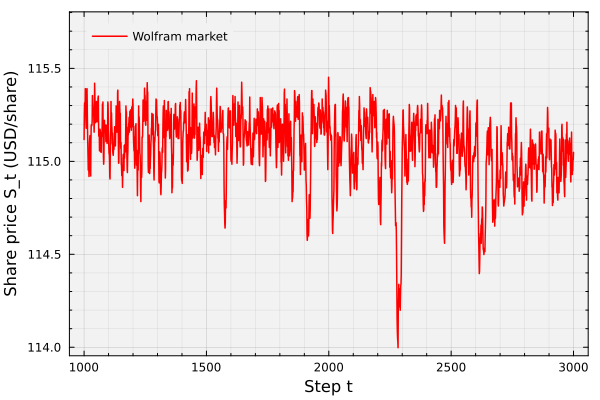

In [5]:
let

    # initialize: the first 2,000 steps after the burn-in -
    window = 1:2_001; # the price at the end of the burn-in and the next 2,000 steps
    t = burn_in .+ (window .- 1); # step numbers

    # plot: the dealer's price -
    q = plot(t, base.S[window], lw = 1.5, c = color_wolfram, label = "Wolfram market",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topleft)

    # labels: leave room for the legend at the top of the axes -
    y_low, y_high = ylims(q);
    ylims!(q, y_low, y_high + 0.2*(y_high - y_low))
    xlabel!(q, "Step t", fontsize = 18)
    ylabel!(q, "Share price S_t (USD/share)", fontsize = 18)
end

Next, let's compare the distribution of the growth rates with a Normal distribution. We standardize the growth rates to mean zero and standard deviation one, so that we compare the shape of the distribution. The legend shows the excess kurtosis from `src/Helper.jl`, which is zero for a Normal distribution.

`Unhide` the code block below to see how we plotted the histogram and the standard Normal curve.

Are the growth rates of the dealer's price Normal?

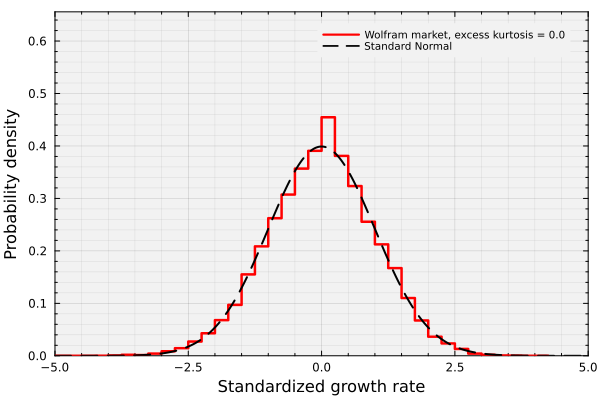

In [6]:
let

    # initialize: the standardized growth rates, and the points for the Normal curve -
    z_limit = 5.0; # the horizontal axis runs from -z_limit to z_limit (standard deviations)
    x = range(-z_limit, z_limit, length = 1_001); # points for the Normal curve (standard deviations)
    z = (base.g .- mean(base.g)) ./ std(base.g); # mean 0, standard deviation 1
    edges = floor(minimum(z)):0.25:(ceil(maximum(z)) + 0.25); # bin edges, 0.25 standard deviations wide, covering every growth rate

    # plot: the outline of the histogram, and the standard Normal curve -
    q = plot(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true,
        xlims = (-z_limit, z_limit), legend = :topright, legendfontsize = 7)
    stephist!(q, z, bins = edges, normalize = :pdf, lw = 2.5, c = color_wolfram,
        label = "Wolfram market, excess kurtosis = $(round(excess_kurtosis(base.g), digits = 1))")
    plot!(q, x, pdf.(Normal(), x), lw = 2, c = :black, ls = :dash, label = "Standard Normal") # the Normal curve

    # labels: leave room for the legend above the histogram -
    ylims!(q, 0, 1.4*ylims(q)[2])
    xlabel!(q, "Standardized growth rate", fontsize = 18)
    ylabel!(q, "Probability density", fontsize = 18)
end

Next, let's consider autocorrelation. For a series with no autocorrelation, 95% of sample autocorrelations fall within about $\pm 1.96/\sqrt{n}$ of zero, where $n$ is the number of growth rates. We call this range the __white-noise band__. [The sample_autocorrelation(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/adaptive/#VLQuantitativeFinancePackage.sample_autocorrelation) computes the autocorrelation at the lags we pass.

`Unhide` the code block below to see how we plotted the autocorrelation of $g$ and of $|g|$ at lags 1 to 50, with the white-noise band.

How long do the autocorrelations last?

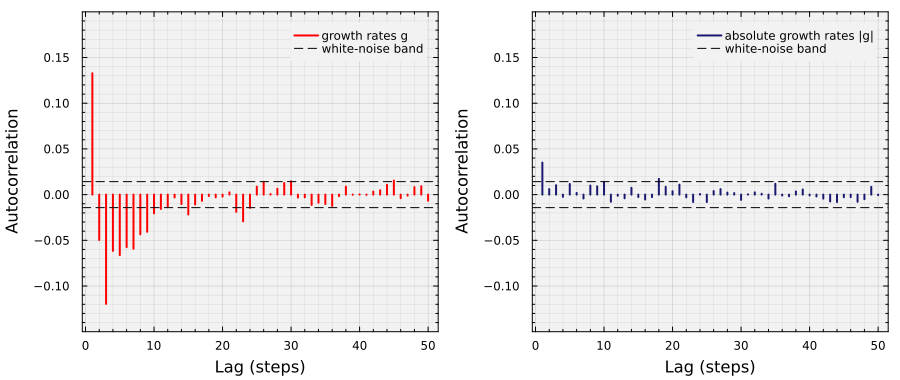

In [7]:
let

    # initialize: the white-noise band of the growth rates -
    band = 1.96/sqrt(length(base.g)); # white-noise band

    # plot: one panel for g, one for |g| -
    panels = [];
    for (series, name, color) ∈ ((base.g, "growth rates g", :red), (abs.(base.g), "absolute growth rates |g|", :midnightblue))
        q = plot(all_lags, sample_autocorrelation(series, all_lags), seriestype = :sticks, lw = 2, c = color, label = name,
            bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
            xminorticks = true, yminorticks = true, minorgrid = true, ylims = (-0.15, 0.2))
        hline!(q, [band, -band], lw = 1, c = :black, ls = :dash, label = "white-noise band") # 95% band for no autocorrelation
        xlabel!(q, "Lag (steps)", fontsize = 18)
        ylabel!(q, "Autocorrelation", fontsize = 18)
        push!(panels, q);
    end

    # show the two panels side by side -
    plot(panels..., layout = (1, 2), size = (900, 380), bottom_margin = 4Plots.mm, left_margin = 4Plots.mm)
end

> __What do we see?__
>
> * __Autocorrelated growth rates:__ The lag-1 autocorrelation of $g$ is positive and far outside the white-noise band. Over the next several lags, the autocorrelation is negative and still outside the band.
> * __Weak, short-lived clustering:__ The autocorrelation of $|g|$ is small at lag 1 and inside the band at almost every later lag.

___

## Task 2: Compare with a Real Ticker and with Farmer–Joshi
In this task, we put the Wolfram market from Task 1 beside the daily growth rates of a real ticker and the Farmer–Joshi market with both groups of traders. The ticker has a wider white-noise band than the two markets, because the band shrinks as the number of growth rates grows.

We leave out markets with a rule switch. After the switch, the price falls and then barely moves, because most interior traders want to Sell but have no shares left.

[The MyFarmerJoshiMarketModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/) builds the Farmer–Joshi market, and `solve(...)` runs it. We store the three series of growth rates, with their names and plot colors, in the `comparison::Vector{NamedTuple}` variable:

In [8]:
comparison = let

    # the real ticker: daily growth rates (1/yr) -
    prices = dataset[ticker].close; # daily closing prices (USD/share)
    g_ticker = (1/Δt) .* diff(log.(prices));

    # the Farmer–Joshi market with both groups of traders -
    rng = MersenneTwister(fj_seed);
    model = build(MyFarmerJoshiMarketModel, (σ_S = fj_σ_S, σ_v = fj_σ_v, Δt = Δt, rng = rng));
    g_fj = solve(model; number_of_steps = fj_steps, burn_in = fj_burn_in, rng = rng).returns ./ Δt;

    # the three series, each with its name and plot color -
    series = [(name = "Wolfram market", g = base.g, color = color_wolfram), (name = ticker, g = g_ticker, color = color_ticker),
        (name = "Farmer–Joshi", g = g_fj, color = color_fj)];
    println("growth rates: ", join(["$(s.name) $(length(s.g))" for s ∈ series], ", "));

    # checks -
    @assert all(all(isfinite, s.g) for s ∈ series) "every growth rate is finite"

    # return -
    series
end;

growth rates: Wolfram market 19000, SPY 2766, Farmer–Joshi 20000

`Unhide` the code block below to see how we plotted the histograms of the standardized growth rates of the three series, as in Task 1. Which series have fat tails?

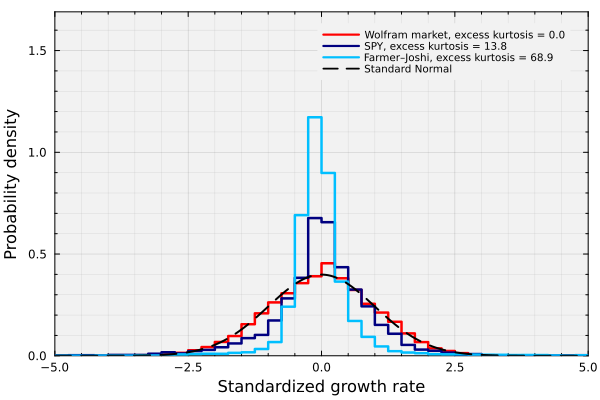

In [9]:
let

    # initialize: the points for the Normal curve -
    z_limit = 5.0; # the horizontal axis runs from -z_limit to z_limit (standard deviations)
    x = range(-z_limit, z_limit, length = 1_001); # points for the Normal curve (standard deviations)

    # plot: the outline of the histogram of the standardized growth rates of each series -
    q = plot(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true,
        xlims = (-z_limit, z_limit), legend = :topright, legendfontsize = 7)
    for s ∈ comparison
        z = (s.g .- mean(s.g)) ./ std(s.g); # mean 0, standard deviation 1
        edges = floor(minimum(z)):0.25:(ceil(maximum(z)) + 0.25); # bin edges, 0.25 standard deviations wide
        stephist!(q, z, bins = edges, normalize = :pdf, lw = 2.5, c = s.color,
            label = "$(s.name), excess kurtosis = $(round(excess_kurtosis(s.g), digits = 1))")
    end
    plot!(q, x, pdf.(Normal(), x), lw = 2, c = :black, ls = :dash, label = "Standard Normal") # the Normal curve

    # labels: leave room for the legend above the tallest histogram -
    ylims!(q, 0, 1.4*ylims(q)[2])
    xlabel!(q, "Standardized growth rate", fontsize = 18)
    ylabel!(q, "Probability density", fontsize = 18)
end

> __What do we see?__ The ticker and Farmer–Joshi histograms rise above the standard Normal curve near the center, and their excess kurtosis is far above zero. Only the Wolfram market's histogram follows the Normal curve.

`Unhide` the code block below to see how we plotted the autocorrelations at lags 1 to 50, with the ticker as sticks and the Wolfram and Farmer–Joshi markets as lines.

How long do the autocorrelations last in each series?

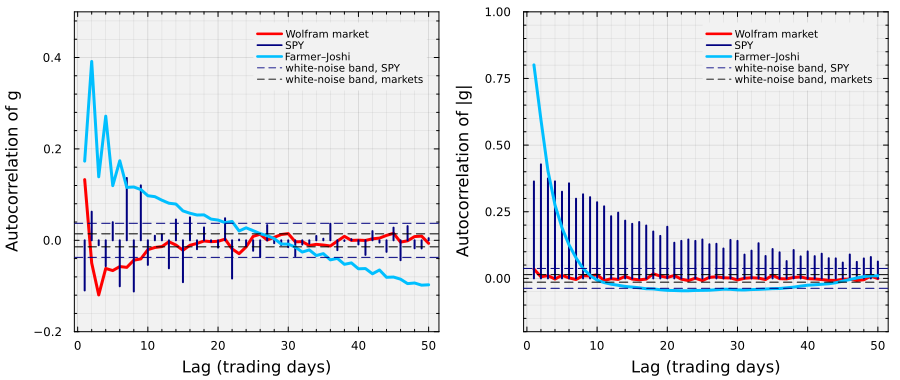

In [10]:
let

    # plot: one panel for g, one for |g| -
    panels = [];
    for (name, y_range) ∈ (("g", (-0.2, 0.5)), ("|g|", (-0.2, 1.0)))
        q = plot(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
            xminorticks = true, yminorticks = true, minorgrid = true, ylims = y_range, legend = :topright, legendfontsize = 7)
        for s ∈ comparison

            # the series we plot -
            x = s.g;
            if name == "|g|"
                x = abs.(s.g);
            end

            # the ticker as sticks, the two markets as lines -
            if s.name == ticker
                plot!(q, all_lags, sample_autocorrelation(x, all_lags), seriestype = :sticks, lw = 2, c = s.color, label = s.name)
            else
                plot!(q, all_lags, sample_autocorrelation(x, all_lags), lw = 3, c = s.color, label = s.name)
            end
        end
        band_ticker = 1.96/sqrt(length(dataset[ticker].close) - 1); # white-noise band of the ticker
        band_markets = 1.96/sqrt(length(base.g)); # white-noise band of the two markets (almost the same length)
        hline!(q, [band_ticker, -band_ticker], lw = 1, c = color_ticker, ls = :dash, label = "white-noise band, $(ticker)")
        hline!(q, [band_markets, -band_markets], lw = 1, c = :black, ls = :dash, label = "white-noise band, markets")
        xlabel!(q, "Lag (trading days)", fontsize = 18)
        ylabel!(q, "Autocorrelation of $(name)", fontsize = 18)
        push!(panels, q);
    end

    # show the two panels side by side -
    plot(panels..., layout = (1, 2), size = (900, 380), bottom_margin = 4Plots.mm, left_margin = 4Plots.mm)
end

> __What do we see?__
>
> * __Volatility clustering:__ The autocorrelation of $|g|$ for the ticker stays above its white-noise band at every lag we plot. The Farmer–Joshi market starts high at lag 1 and then falls to about zero. The Wolfram market's autocorrelation is inside its band at almost every lag after lag 1.
> * __Autocorrelation of $g$:__ At lag 1, the autocorrelation of $g$ is positive for the Wolfram market and the Farmer–Joshi market, and negative for the ticker. The Farmer–Joshi market differs from the one in the Farmer–Joshi example, because we build it from a fresh random stream, which gives different traders and different random moves.

___

## Task 3: What Changes the Statistics?
In this task, we ask whether traders who react to the price change the tails and autocorrelations of the growth rates. Only the traders on the edge of the grid watch the price. We run the edge traders three ways. 

__Active__ edge traders buy when the price is well below its recent average and sell when it is well above it. __Held__ edge traders always hold, and __random__ edge traders pick Buy, Hold, or Sell at random. We also run the active case with a __shallow dealer__, which moves the price more for each trade than the deep dealer we have used so far. 

We run each case three times, from different seeds, and average the results. We store the averages in the `feedback::Vector{NamedTuple}` variable:

In [11]:
feedback = let

    # initialize: the conditions (edge traders, dealer depth, name, plot color) -
    conditions = [(:endogenous, h_deep, "deep dealer, active edge", color_wolfram), (:hold, h_deep, "deep dealer, held edge", :navy),
        (:random, h_deep, "deep dealer, random edge", :deepskyblue1), (:endogenous, h_shallow, "shallow dealer, active edge", :green4)];
    results = NamedTuple[];

    # main loop: average the statistics over the starting markets in each condition -
    t_total = @elapsed for (mode, h, name, color) ∈ conditions
        acf_g = zeros(length(all_lags)); # average autocorrelation of g at each lag
        acf_absolute_g = zeros(length(all_lags)); # average autocorrelation of |g| at each lag
        mean_kurtosis = 0.0; # average excess kurtosis
        for sd ∈ seeds
            r = run_baseline(rule = baseline_rule, L = L, h = h, boundary_mode = mode, seed = sd, steps = steps);
            g = (1/Δt) .* diff(log.(r.prices[(burn_in + 1):end])); # growth rates (1/yr)
            acf_g .+= sample_autocorrelation(g, all_lags) ./ length(seeds);
            acf_absolute_g .+= sample_autocorrelation(abs.(g), all_lags) ./ length(seeds);
            mean_kurtosis += excess_kurtosis(g) / length(seeds);
        end
        push!(results, (name = name, color = color, acf_g = acf_g, acf_absolute_g = acf_absolute_g, kurtosis = mean_kurtosis));
    end
    println("run time: $(round(t_total; digits = 1)) seconds; $(length(seeds)) starting markets per condition");

    # checks -
    @assert length(results) == length(conditions) "one result for each condition"

    # return -
    results
end;

run time: 4.3 seconds; 3 starting markets per condition


`Unhide` the code block below to see how we plotted the average autocorrelations of each case at lags 1 to 50, with the white-noise band. The legend shows the average excess kurtosis of each case.

Which case changes the autocorrelations?

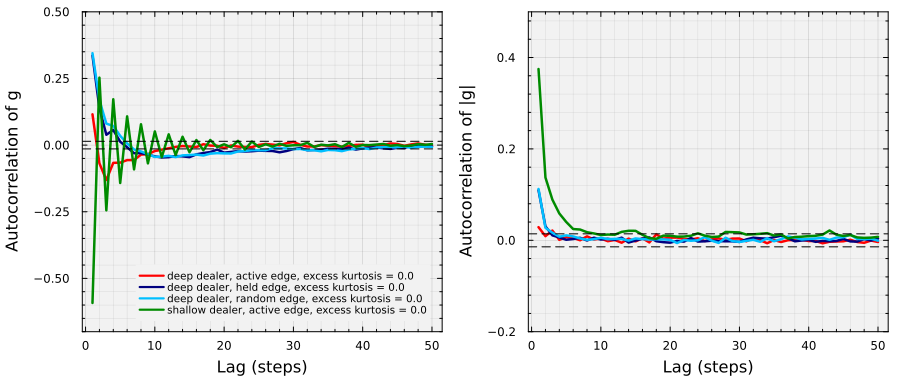

In [12]:
let

    # initialize: the white-noise band of one market -
    band = 1.96/sqrt(steps - burn_in); # white-noise band

    # plot: one panel for g, one for |g| -
    panels = [];
    for (name, y_range) ∈ (("g", (-0.7, 0.5)), ("|g|", (-0.2, 0.5)))
        q = plot(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
            xminorticks = true, yminorticks = true, minorgrid = true, ylims = y_range, legend = :bottomright, legendfontsize = 7)
        for c ∈ feedback
            values = c.acf_g;
            label_text = "$(c.name), excess kurtosis = $(round(c.kurtosis, digits = 1) + 0.0)"; # adding 0.0 turns -0.0 into 0.0
            if name == "|g|"
                values = c.acf_absolute_g;
                label_text = "";
            end
            plot!(q, all_lags, values, lw = 2.5, c = c.color, label = label_text)
        end
        hline!(q, [band, -band], lw = 1, c = :black, ls = :dash, label = "") # 95% band for no autocorrelation
        xlabel!(q, "Lag (steps)", fontsize = 18)
        ylabel!(q, "Autocorrelation of $(name)", fontsize = 18)
        push!(panels, q);
    end

    # show the two panels side by side -
    plot(panels..., layout = (1, 2), size = (900, 380), bottom_margin = 4Plots.mm, left_margin = 4Plots.mm)
end

> __What do we see?__
>
> * __No case gives fat tails:__ The excess kurtosis is close to zero in every case.
> * __Watching the price lowers the autocorrelation of $g$:__ With a deep dealer, the lag-1 autocorrelation of $g$ is much smaller when the edge traders are active than when they are held or random. Held and random edge traders both ignore the price, and their curves almost match.
> * __A shallow dealer makes the price reverse:__ The lag-1 autocorrelation of $g$ is strongly negative: a rise is usually followed by a fall. The lag-1 autocorrelation of $|g|$ rises well above the deep-dealer cases. The ticker's lag-1 autocorrelation of $g$ is also negative, but much smaller.

___

## Summary
In this example, we measured the stylized facts of a Wolfram market's price, compared them with a real ticker and the Farmer–Joshi market, and tested whether traders who watch the price, or a shallow dealer, change the statistics.

> __Key Takeaways:__
>
> * __A model price can be measured like a real one:__ We computed the growth rates of the dealer's price in a Wolfram market that never switches, and measured their tails and autocorrelations. Its growth rates have tails close to Normal, a positive lag-1 autocorrelation, and only weak, short-lived clustering.
> * __The Wolfram market does not look like a real market:__ We put its statistics beside a real ticker and the Farmer–Joshi market, which both show fat tails and volatility clustering. The Wolfram market shows no fat tails and little clustering, because it was built to study rule switches, not price statistics.
> * __Watching the price changes the autocorrelations, not the tails:__ We compared edge traders who watch the price with edge traders who ignore it, and a deep dealer with a shallow one. Traders who watch the price lowered the autocorrelation of the growth rates, and a shallow dealer made it negative. No case produced fat tails.

A model built to answer one question can fail another, and measuring both is how we learn what a model is for.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___